In [ ]:
# Cell 1 — Imports & Config
import os, json, pickle, warnings
import numpy as np
import pandas as pd
from scipy import signal as spsig
from scipy.spatial.transform import Rotation
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

GESTURES    = ['goodbye', 'thanks', 'welcome']
GESTURE_DIR = '../data/'
MODELS_DIR  = '../models/'
WIN          = 100
TRAIN_STRIDE = 10
STRIDE       = 25
AUG_COPIES   = 30
FS_TARGET    = 50.0
G            = 9.81

CLASSES   = GESTURES
LABEL_MAP = {g: i for i, g in enumerate(GESTURES)}

COLS = ['xAcc','yAcc','zAcc','xGyro','yGyro','zGyro']



FEATURE_NAMES = (
    [f'std_{ax}'   for ax in COLS] +   # 6
    [f'range_{ax}' for ax in COLS] +   # 6
    [f'zcr_{ax}'   for ax in COLS] +   # 6
    ['mag_accel_mean','mag_accel_std','mag_accel_min','mag_accel_max',
     'mag_accel_range','mag_accel_energy','mag_accel_zcr'] +   # 7
    ['mag_gyro_mean','mag_gyro_std','mag_gyro_min','mag_gyro_max',
     'mag_gyro_range','mag_gyro_energy','mag_gyro_zcr']        # 7
)

os.makedirs(MODELS_DIR, exist_ok=True)
print(f'Feature vector length : {len(FEATURE_NAMES)}')
print(f'Classes               : {CLASSES}')
print(f'\nCWD: {os.getcwd()}')
print(f'MODELS_DIR  resolved: {os.path.abspath(MODELS_DIR)}')
for g in GESTURES:
    p = GESTURE_DIR + f'{g}_training_data.csv'
    rows = sum(1 for _ in open(p)) - 1 if os.path.exists(p) else 'MISSING'
    print(f'  {g}_training_data.csv: {rows} rows')


Feature vector length : 32
Classes               : ['goodbye', 'thanks', 'welcome']

CWD: c:\Users\asaad\OneDrive\Desktop\last try\neuropath_notebooks\neuropath\notebooks
MODELS_DIR  resolved: c:\Users\asaad\OneDrive\Desktop\last try\neuropath_notebooks\neuropath\models
  goodbye_training_data.csv: 15833 rows
  thanks_training_data.csv: 10515 rows
  welcome_training_data.csv: 11036 rows


## Step 1 — Load & Clean Gesture CSVs

Drops corrupted USB driver rows, detects sample rate, resamples to 50 Hz.

In [48]:
# Cell 2 — Load gesture CSVs
def load_gesture_csv(name):
    path = GESTURE_DIR + f'{name}_training_data.csv'
    df = pd.read_csv(path)
    # Force all columns numeric; drop rows with any NaN (corrupted USB rows)
    for col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    df = df.dropna().reset_index(drop=True)

    # Detect recorded sample rate from timestamp gaps
    ts = df['Timestamp'].values
    diffs = np.diff(ts)
    diffs = diffs[(diffs > 0) & (diffs < 1)]  # ignore bad gaps
    fs_rec = round(1.0 / np.median(diffs)) if len(diffs) else FS_TARGET
    print(f'{name:12s}: {len(df):6,} rows | detected {fs_rec} Hz', end='')

    data = df[['Accel_X','Accel_Y','Accel_Z','Gyro_X','Gyro_Y','Gyro_Z']].values

    # Resample to 50 Hz if needed
    if abs(fs_rec - FS_TARGET) > 3:
        n_out = int(round(len(data) * FS_TARGET / fs_rec))
        data  = spsig.resample(data, n_out)
        print(f' → resampled to {FS_TARGET} Hz ({len(data):,} rows)', end='')
    print()

    result = pd.DataFrame(data, columns=COLS)
    result['label'] = LABEL_MAP[name]
    return result

dfs_gesture = [load_gesture_csv(g) for g in GESTURES]
total_gesture = sum(len(d) for d in dfs_gesture)
print(f'\nTotal gesture samples : {total_gesture:,}')


goodbye     : 15,831 rows | detected 77 Hz → resampled to 50.0 Hz (10,280 rows)
thanks      : 10,513 rows | detected 77 Hz → resampled to 50.0 Hz (6,827 rows)
welcome     : 11,034 rows | detected 77 Hz → resampled to 50.0 Hz (7,165 rows)

Total gesture samples : 24,272


## Step 2 — Load Idle Data

`normal_hand_data.csv` is in g/deg/s — convert to m/s²/rad/s to match gesture CSVs.

In [49]:
# Cell 3 — Idle class SKIPPED
# normal_hand_data.csv records gravity only on the X-axis (sensor resting flat).
# The live glove distributes gravity across all three axes depending on hand orientation.
# This orientation mismatch makes idle features unrepresentative of real idle → skipped.
# The motion gate (std < 1.0 m/s²) handles still-hand suppression at inference time.
print('Idle class removed — motion gate handles still-hand detection.')
print('Classes: goodbye / thanks / welcome  (3-class model)')


Idle class removed — motion gate handles still-hand detection.
Classes: goodbye / thanks / welcome  (3-class model)


In [ ]:


def extract_features(win: np.ndarray) -> np.ndarray:
    """32 orientation-invariant features.

    Per-axis (3 × 6 = 18):  std, range, ZCR (mean-centred)
    Magnitude    (7 × 2 = 14): mean, std, min, max, range, energy, ZCR
                                for accel_mag and gyro_mag
    """
    n    = win.shape[0]
    mean = np.mean(win, axis=0)
    std  = np.std(win,  axis=0)
    mn   = np.min(win,  axis=0)
    mx   = np.max(win,  axis=0)
    rng  = mx - mn

    # ZCR centred on the local mean — eliminates gravity bias on accel axes
    zcr = np.array([
        np.sum(np.diff(np.sign(win[:, i] - mean[i])) != 0) / n
        for i in range(win.shape[1])
    ])

    accel_mag = np.sqrt(np.sum(win[:, :3] ** 2, axis=1))
    gyro_mag  = np.sqrt(np.sum(win[:, 3:6] ** 2, axis=1))

    def _mag_feats(mag: np.ndarray) -> np.ndarray:
        m_mean = np.mean(mag); m_std = np.std(mag)
        m_min  = np.min(mag);  m_max = np.max(mag)
        return np.array([
            m_mean, m_std, m_min, m_max,
            m_max - m_min,
            float(np.sum(mag ** 2)),
            np.sum(np.diff(np.sign(mag - m_mean)) != 0) / n,
        ])

    feat = np.concatenate([std, rng, zcr,
                           _mag_feats(accel_mag), _mag_feats(gyro_mag)])
    assert len(feat) == len(FEATURE_NAMES), f"Feature count mismatch: {len(feat)} vs {len(FEATURE_NAMES)}"
    return feat

# Smoke test
_f = extract_features(np.random.randn(100, 6))
print(f'Feature vector: {len(_f)} features  (expected {len(FEATURE_NAMES)})')
print(f'Names sample  : {FEATURE_NAMES[:4]}  ...  {FEATURE_NAMES[-3:]}')


Feature vector: 32 features  (expected 32)
Names sample  : ['std_xAcc', 'std_yAcc', 'std_zAcc', 'std_xGyro']  ...  ['mag_gyro_range', 'mag_gyro_energy', 'mag_gyro_zcr']


## Step 4 — Build Raw Windows

In [51]:
# Cell 5 — Sliding window stats (display only — actual split happens in Cell 7)
def get_windows(df, stride=STRIDE):
    data = df[COLS].values
    wins = []
    for s in range(0, len(data) - WIN + 1, stride):
        wins.append(data[s : s + WIN])
    return wins

total = 0
for df, g in zip(dfs_gesture, GESTURES):
    w = get_windows(df)
    print(f'{g:12s}: {len(w):4d} raw windows  ({len(df):,} rows)')
    total += len(w)
print(f'\nTotal raw gesture windows (stride {STRIDE}): {total}')


goodbye     :  408 raw windows  (10,280 rows)
thanks      :  270 raw windows  (6,827 rows)
welcome     :  283 raw windows  (7,165 rows)

Total raw gesture windows (stride 25): 961


## Step 5 — Data Augmentation (gesture classes only, 20× per window)

| Technique | Parameters |
|-----------|------------|
| Jittering | σ=0.196 m/s² accel, σ=0.00873 rad/s gyro |
| Amplitude scaling | random ×[0.8, 1.2] |
| Time-warp | stretch ±20%, resample back to 100 samples |
| Axis rotation | random ±15° on accel axes |

In [52]:
# Cell 6 — Augmentation function (called later on train split only)
_rng = np.random.default_rng(0)

def augment_one(win: np.ndarray) -> np.ndarray:
    """Return one augmented copy of a (WIN, 6) window."""
    w = win.copy().astype(np.float64)
    w[:, :3] += _rng.normal(0, 0.196,   (WIN, 3))
    w[:, 3:] += _rng.normal(0, 0.00873, (WIN, 3))
    w *= _rng.uniform(0.8, 1.2)
    warp   = _rng.uniform(0.8, 1.2)
    n_warp = max(int(WIN * warp), WIN // 2)
    w      = spsig.resample(w, n_warp)
    w      = spsig.resample(w, WIN)
    angle  = _rng.uniform(-15, 15)
    axis   = _rng.choice(['x', 'y', 'z'])
    rot    = Rotation.from_euler(axis, angle, degrees=True)
    w[:, :3] = rot.apply(w[:, :3])
    return w

print('augment_one() ready.')


augment_one() ready.


## Step 6 — Extract Features & Build Dataset

In [53]:
# Cell 7 — Time-based split + augmentation (gesture classes only)
raw_tr_wins, raw_te_wins = [], []
raw_tr_lbls, raw_te_lbls = [], []

def _slice_windows(df_slice, stride):
    data = df_slice[COLS].values
    wins = []
    for s in range(0, len(data) - WIN + 1, stride):
        wins.append(data[s : s + WIN])
    return wins

for df, g in zip(dfs_gesture, GESTURES):
    split_row = int(len(df) * 0.80)
    tr_wins   = _slice_windows(df.iloc[:split_row], TRAIN_STRIDE)
    te_wins   = _slice_windows(df.iloc[split_row:], STRIDE)
    raw_tr_wins.extend(tr_wins);  raw_tr_lbls.extend([LABEL_MAP[g]] * len(tr_wins))
    raw_te_wins.extend(te_wins);  raw_te_lbls.extend([LABEL_MAP[g]] * len(te_wins))
    print(f'{g:12s}: {len(tr_wins):4d} train (stride {TRAIN_STRIDE}) | {len(te_wins):3d} test (stride {STRIDE})')

# Augment all training windows (all are gesture classes)
aug_tr_wins, aug_tr_lbls = [], []
for w, l in zip(raw_tr_wins, raw_tr_lbls):
    aug_tr_wins.append(w)
    aug_tr_lbls.append(l)
    for _ in range(AUG_COPIES):
        aug_tr_wins.append(augment_one(w))
        aug_tr_lbls.append(l)

print(f'\nTrain (augmented) : {len(aug_tr_wins):,}')
print(f'Test  (originals) : {len(raw_te_wins):,}')

print('Extracting training features...')
X_tr = np.array([extract_features(w) for w in aug_tr_wins])
y_tr = np.array(aug_tr_lbls, dtype=int)

print('Extracting test features...')
X_te = np.array([extract_features(w) for w in raw_te_wins])
y_te = np.array(raw_te_lbls, dtype=int)

print(f'X_tr: {X_tr.shape} | X_te: {X_te.shape}')
for i, cls in enumerate(CLASSES):
    print(f'  {cls:10s}: train={int((y_tr==i).sum()):,}  test={int((y_te==i).sum())}')


goodbye     :  813 train (stride 10) |  79 test (stride 25)
thanks      :  537 train (stride 10) |  51 test (stride 25)
welcome     :  564 train (stride 10) |  54 test (stride 25)

Train (augmented) : 59,334
Test  (originals) : 184
Extracting training features...
Extracting test features...
X_tr: (59334, 32) | X_te: (184, 32)
  goodbye   : train=25,203  test=79
  thanks    : train=16,647  test=51
  welcome   : train=17,484  test=54


## Step 7 — Train: SVM vs Random Forest

In [54]:
# Cell 8 — Train SVM vs Random Forest (fast — under 60 seconds total)
le = LabelEncoder()
y_tr_enc = le.fit_transform(y_tr)
y_te_enc = le.transform(y_te)

scaler = StandardScaler()
X_tr_s = scaler.fit_transform(X_tr)
X_te_s = scaler.transform(X_te)

print('Training SVM (RBF)...')
svm = SVC(kernel='rbf', C=10, gamma='scale', probability=True,
          class_weight='balanced', random_state=42)
svm.fit(X_tr_s, y_tr_enc)
svm_acc = accuracy_score(y_te_enc, svm.predict(X_te_s))
print(f'  SVM  accuracy: {svm_acc:.4f}')

print('Training Random Forest...')
rf = RandomForestClassifier(n_estimators=300, max_depth=None,
                             class_weight='balanced', random_state=42, n_jobs=-1)
rf.fit(X_tr, y_tr_enc)
rf_acc = accuracy_score(y_te_enc, rf.predict(X_te))
print(f'  RF   accuracy: {rf_acc:.4f}')

if svm_acc >= rf_acc:
    BEST, BEST_NAME, BEST_NEEDS_SCALER = svm, 'SVM', True
    best_pred = svm.predict(X_te_s)
else:
    BEST, BEST_NAME, BEST_NEEDS_SCALER = rf, 'RandomForest', False
    best_pred = rf.predict(X_te)

print(f'\n→ Best model: {BEST_NAME}')
print(classification_report(y_te_enc, best_pred, target_names=CLASSES))


Training SVM (RBF)...
  SVM  accuracy: 1.0000
Training Random Forest...
  RF   accuracy: 1.0000

→ Best model: SVM
              precision    recall  f1-score   support

     goodbye       1.00      1.00      1.00        79
      thanks       1.00      1.00      1.00        51
     welcome       1.00      1.00      1.00        54

    accuracy                           1.00       184
   macro avg       1.00      1.00      1.00       184
weighted avg       1.00      1.00      1.00       184



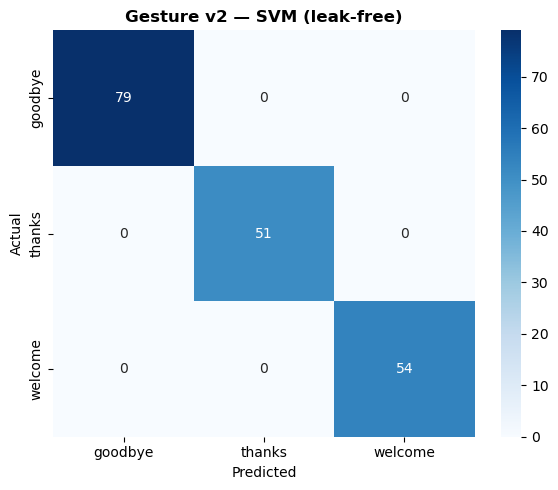

5-fold CV balanced accuracy (original windows, no leakage): 0.9988 ± 0.0025
Holdout test accuracy                                      : 1.0000


In [55]:
# Cell 9 — Confusion matrix + cross-validation (leak-free)
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_te_enc, best_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
ax.set_title(f'Gesture v2 — {BEST_NAME} (leak-free)', fontweight='bold')
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout()
plt.savefig(MODELS_DIR + 'gesture_evaluation_v2.png', dpi=120, bbox_inches='tight')
plt.show()

# CV on ORIGINAL (non-augmented) training windows only.
# Running on augmented X_tr inflates CV to ~1.0 due to near-identical clones in each fold.
X_tr_orig     = np.array([extract_features(w) for w in raw_tr_wins])
y_tr_orig_enc = le.transform(np.array(raw_tr_lbls, dtype=int))
X_cv_orig     = scaler.transform(X_tr_orig) if BEST_NEEDS_SCALER else X_tr_orig

cv = cross_val_score(BEST, X_cv_orig, y_tr_orig_enc,
                     cv=StratifiedKFold(5, shuffle=True, random_state=42),
                     scoring='balanced_accuracy', n_jobs=-1)
print(f'5-fold CV balanced accuracy (original windows, no leakage): {cv.mean():.4f} ± {cv.std():.4f}')
print(f'Holdout test accuracy                                      : {accuracy_score(y_te_enc, best_pred):.4f}')
if cv.mean() < 0.70:
    print('WARNING: Low CV accuracy — model likely overfit. Record more diverse data across sessions.')


## Step 8 — Save Model Artifacts

In [56]:
# Cell 10 — Save all model artifacts
with open(MODELS_DIR + 'gesture_brain_v2.pkl',          'wb') as f: pickle.dump(BEST,   f)
with open(MODELS_DIR + 'gesture_scaler_v2.pkl',         'wb') as f: pickle.dump(scaler, f)
with open(MODELS_DIR + 'gesture_label_encoder_v2.pkl',  'wb') as f: pickle.dump(le,     f)

config = {
    'model_type'          : BEST_NAME,
    'needs_scaler'        : BEST_NEEDS_SCALER,
    'classes'             : CLASSES,
    'feature_names'       : FEATURE_NAMES,
    'feature_count'       : len(FEATURE_NAMES),
    'window_size'         : WIN,
    'train_stride'        : TRAIN_STRIDE,
    'test_stride'         : STRIDE,
    'sampling_hz'         : int(FS_TARGET),
    'aug_copies'          : AUG_COPIES,
    'motion_threshold'    : 1.0,
    'confidence_threshold': 0.55,
    'cooldown_s'          : 2.0,
    'test_accuracy'       : round(float(accuracy_score(y_te_enc, best_pred)), 4),
    'cv_bal_accuracy'     : round(float(cv.mean()), 4),
    'train_windows'       : int(X_tr.shape[0]),
    'test_windows'        : int(X_te.shape[0]),
}
with open(MODELS_DIR + 'gesture_model_config_v2.json', 'w') as f:
    json.dump(config, f, indent=2)

print('Saved:')
for fname in ['gesture_brain_v2.pkl','gesture_scaler_v2.pkl',
              'gesture_label_encoder_v2.pkl','gesture_model_config_v2.json',
              'gesture_evaluation_v2.png']:
    path = MODELS_DIR + fname
    size = os.path.getsize(path) / 1024
    print(f'  {fname:42s} {size:7.1f} KB')
print(f'\nTest accuracy : {config["test_accuracy"]:.4f}')
print(f'CV  accuracy  : {config["cv_bal_accuracy"]:.4f}  (honest — no augmentation leakage)')
print(f'Features      : {config["feature_count"]}  (18 orientation-invariant per-axis + 14 magnitude)')


Saved:
  gesture_brain_v2.pkl                          84.6 KB
  gesture_scaler_v2.pkl                          1.2 KB
  gesture_label_encoder_v2.pkl                   0.2 KB
  gesture_model_config_v2.json                   1.1 KB
  gesture_evaluation_v2.png                     29.1 KB

Test accuracy : 1.0000
CV  accuracy  : 0.9988  (honest — no augmentation leakage)
Features      : 32  (18 orientation-invariant per-axis + 14 magnitude)
